# Part 1: Import Packages

In [1]:
%pip install ucimlrepo

# Data Processing
import numpy as np
import pandas as pd

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Data Transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Calibration
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import CalibrationDisplay
from sklearn.frozen import FrozenEstimator

# Model Evaluation
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import brier_score_loss, log_loss

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Data Source
from ucimlrepo import fetch_ucirepo

To ensure our experiment is reproducible, we will set a single seed (42) to be used throughout the training.

In [2]:
SEED = 42

# Part 2: Importing Dataset

The dataset was loaded from the UCI repository as a feature table plus a target column. From [UCI](#https://archive.ics.uci.edu/dataset/94/spambase), Spambase has 4,601 rows and 57 numeric features, with no missing values.

In [3]:
# fetch spam dataset
spambase = fetch_ucirepo(id=94)
spam_df = pd.concat((spambase.data.features, spambase.data.targets), axis=1)

# variable information
print(spambase.variables)

                          name     role        type demographic  \
0               word_freq_make  Feature  Continuous        None   
1            word_freq_address  Feature  Continuous        None   
2                word_freq_all  Feature  Continuous        None   
3                 word_freq_3d  Feature  Continuous        None   
4                word_freq_our  Feature  Continuous        None   
5               word_freq_over  Feature  Continuous        None   
6             word_freq_remove  Feature  Continuous        None   
7           word_freq_internet  Feature  Continuous        None   
8              word_freq_order  Feature  Continuous        None   
9               word_freq_mail  Feature  Continuous        None   
10           word_freq_receive  Feature  Continuous        None   
11              word_freq_will  Feature  Continuous        None   
12            word_freq_people  Feature  Continuous        None   
13            word_freq_report  Feature  Continuous        Non

In [4]:
# See the first 5 spam samples
spam_df.head(5)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [5]:
# See data types in each column
spam_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 

## 2.1. Correlation Matrix

We will use a **correlation matrix** to identify features that are highly correlated with each other and decide which columns to be used for our models.

In [6]:
correlation_matrix = spam_df.corr(numeric_only=True)

# Plot heatmap of correlation matrix
fig = go.Figure(data=go.Heatmap(
   z=correlation_matrix,
   x=correlation_matrix.columns,
   y=correlation_matrix.index,
   colorscale='RdBu_r',
   text=correlation_matrix.round(2),
   texttemplate='%{text}',
   textfont={"size": 10},
   hoverongaps=False,
   zmin=-1
))

fig.update_layout(
   width=2500,
   height=2500,
   title='Correlation Matrix Heatmap',
   xaxis_title='',
   yaxis_title='',
   yaxis=dict(autorange='reversed')
)

We observed features that are highly correlated with each other:
- `word_freq_857` and `word_freq_415` --> $\rho=1$ (correlation)
- `word_freq_direct` and `word_freq_857` --> $\rho=0.85$
- `word_freq_direct` and `word_freq_415` --> $\rho=0.85$

Since the first pair has a perfect correlation, we can safely drop the column `word_freq_857` from the dataset. Even though the remaining pairs are highly correlated, we want to keep them for Random Forest because ensemble models (in this case, **bagging**) can handle correlated features well. However, multicollinearity will dillute the coefficients in Logistic Regression, so (later) we will drop the column `word_freq_direct` only for training this baseline model.

In [7]:
spam_df.drop('word_freq_857', axis=1, inplace=True)

In [8]:
# Check if there are any duplicate rows in the dataset
spam_df[spam_df.duplicated(keep=False)]

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
24,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
26,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
101,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
102,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
103,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4441,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4537,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,6,0
4541,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,2,0


## 2.2. Grouping

In real scenarios, spam messages often have the same exact information, so duplicate samples also serve as a signal of repeating events. Thus, instead of simply removing them, we will group the duplicates and giving unique samples with unique ids.

In [9]:
spam_feature_cols = [col for col in spam_df.columns if col != 'Class']
X_spam, y_spam = spam_df[spam_feature_cols], spam_df['Class']

# Check class balance
print(f"Original Balance: {y_spam.mean():.2%} spam")

# Creating group ids (identical rows share the same id)
groups = spam_df.groupby(spam_feature_cols).ngroup()
print(f"{len(spam_df)} samples --> {groups.max() + 1} groups")

# Count identical rows with conflicting labels
conflicts = spam_df.groupby(groups)['Class'].nunique().gt(1).sum()
print(f"Groups with conflicting labels: {conflicts}")

Original Balance: 39.40% spam
4601 samples --> 4207 groups
Groups with conflicting labels: 3


## 2.3. Splitting

Due to the class imbalance, we want to use a stratified split. Since we also want to split the **duplicate-grouped** dataset into training, calibration, validation, and testing sets, we will use `StrateifiedGroupKFold` to satisfy all of these criterions.

In [10]:
# 10 stratified folds that never split a group
fold = np.empty(len(spam_df), dtype=int)
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
for k, (_, idx) in enumerate(sgkf.split(X_spam, y_spam, groups)):
    fold[idx] = k

# Split 40% train, 30% calibration pool, 10% validation, 20% test
part = np.select([fold < 4, fold < 7, fold < 8], ['train', 'cal', 'val'], 'test')

# Select rows from X_spam that correspond to rows in `part` that are labelled as 'train'
X_spam_train, y_spam_train = X_spam[part == 'train'], y_spam[part == 'train']

X_spam_cal,   y_spam_cal   = X_spam[part == 'cal'],   y_spam[part == 'cal']
X_spam_val,   y_spam_val   = X_spam[part == 'val'],   y_spam[part == 'val']
X_spam_test,  y_spam_test  = X_spam[part == 'test'],  y_spam[part == 'test']

# Check every group belongs to exactly one set, and class balance is preserved
assert (pd.Series(part).groupby(groups.values).nunique() == 1).all()
print(pd.Series(y_spam.values).groupby(part).agg(['size', 'mean']))

       size      mean
cal    1404  0.397436
test    955  0.392670
train  1791  0.392518
val     451  0.392461


# Part 3: Logistic Regression

## 3.1. Custom Functions

### 3.1.1. Estimator Pipeline

Preprocessing (one-hot encoding and scaling) is wrapped in a `Pipeline` with the classifier. During cross-validation, the encoder and scaler are refit on each training fold only, so no information from the validation fold leaks into preprocessing.

<u>Idea:</u> Automatically perform `.fit_transform()` on the training set and `.transform()` on the held-out data during preprocessing.

In [11]:
def create_pipeline(model, categorical_features, numerical_features, drop_features=None, drop=None):
    # Set up column transformer to encode categorical features and
    # scale numerical features
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop=drop), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]

    if drop_features:
        print('sushi')
        transformers.append(('drop_cols', 'drop', drop_features))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder='passthrough',
        force_int_remainder_cols=False
    )

    # Set up pipeline with column transformer and inputted model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    return pipeline

### 3.1.2. Score Function

Compute the Brier and Log-Loss scores of the model, as well as its expected cost, to evaluate the model's performance.

In [12]:
def score(model, X, y, c_fp, c_fn):
    threshold = c_fp / (c_fp + c_fn)
    p = model.predict_proba(X)[:, 1]
    pred = p > threshold
    cost = (c_fp * np.sum(pred & (y == 0)) + c_fn * np.sum(~pred & (y == 1))) / len(y)
    return brier_score_loss(y, p), log_loss(y, p), cost

## 3.2 Model Training

For the baseline, we will tune the hyperparameter `C` of the Logistic Regression model using the stratified 5-fold CV on the **training set** (`X_spam_train`, `y_spam_train`). We then draw a **reliability diagram** of the model evaluated on the **validation set** (`X_spam_val`, `y_spam_val`).

sushi
Best CV Log Loss: 0.2209
Best Hyperparameters: {'classifier__C': 1}


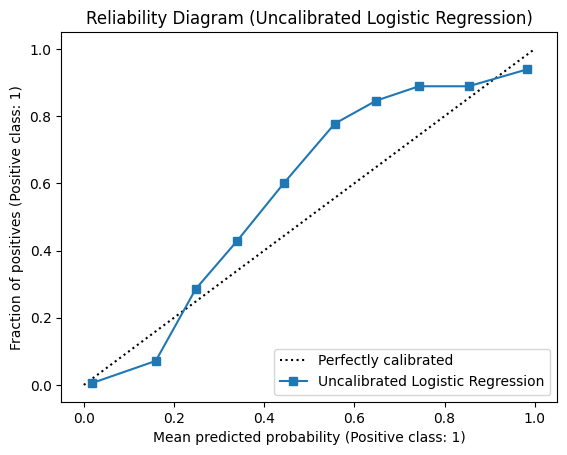

In [13]:
# Tune and train the logistic regression model on training data
train_group = groups[part == 'train']
cv = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X_spam_train, y_spam_train, train_group))

# Drop the highly-correlated column 'word_freq_direct'
lr_numerical_features = [col for col in spam_feature_cols if col != 'word_freq_direct']
spam_lr = create_pipeline(LogisticRegression(max_iter=2000, random_state=SEED),
                        [], lr_numerical_features, drop_features=['word_freq_direct'], drop='first')

param_grid = {'classifier__C': [0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(spam_lr, param_grid, cv=cv, scoring='neg_log_loss', n_jobs=-1)
grid_search.fit(X_spam_train, y_spam_train)

# Output tuning results
print(f"Best CV Log Loss: {abs(grid_search.best_score_):.4f}")
print("Best Hyperparameters:", grid_search.best_params_)

# Get the best model
spam_lr = grid_search.best_estimator_

# Draw reliability diagram on validation set
CalibrationDisplay.from_estimator(spam_lr, X_spam_val, y_spam_val, n_bins=10, name="Uncalibrated Logistic Regression")
plt.title("Reliability Diagram (Uncalibrated Logistic Regression)")
plt.show()

## 3.3. Model Calibration

Missing a spam email (**False Negative - FN**) is generally not as costly as missing a real, potentially critical email (**False Positive - FP**). Consequently, we set the cost of a false positive to be significantly higher than a false negative ($C_{FP} > C_{FN}$).

In this section, we evaluate calibration techniques on our tuned Logistic Regression baseline. For each cost ratio, we randomly draw subsamples of sizes $n \in \{100, 250, 500, 1000\}$ from the **calibration set** (`X_spam_cal`, `y_spam_cal`) and fit both Platt Scaling (`sigmoid`) and `isotonic` regression. We then compute Brier scores, Log-Loss, and expected decision costs on the **validation set** (`X_spam_val`, `y_spam_val`) using the `score()` function. This procedure is repeated over 50 random calibration draws to capture performance distributions.

**Note**: $n=0$ represents the uncalibrated model baseline. We wrap our baseline model inside a `FrozenEstimator` to ensure that `CalibratedClassifierCV` uses the calibration set strictly to learn probability corrections without altering the weights already learned on the training set.

In [15]:
# Cost ratios
C_FP, C_FN = (1, 5, 20), 1

rng = np.random.default_rng(SEED)
N_DRAWS = 50
rows = []
for c_fp in C_FP:
    rows.append((c_fp, 'none', 0, *score(spam_lr, X_spam_val, y_spam_val, c_fp, C_FN)))
    for n in (100, 250, 500, 1000):
        for _ in range(N_DRAWS):
            idx = rng.choice(len(y_spam_cal), n, replace=False)
            for method in ('sigmoid', 'isotonic'):
                cal = CalibratedClassifierCV(FrozenEstimator(spam_lr), method=method)
                cal.fit(X_spam_cal.iloc[idx], y_spam_cal.iloc[idx])
                rows.append((c_fp, method, n, *score(cal, X_spam_val, y_spam_val, c_fp, C_FN)))

lr_calibration_results = pd.DataFrame(rows, columns=['c_fp', 'method', 'n', 'brier', 'logloss', 'cost'])

print(lr_calibration_results.groupby(['c_fp', 'method', 'n']).agg(['mean', 'std']).round(4))

                     brier         logloss            cost        
                      mean     std    mean     std    mean     std
c_fp method   n                                                   
1    isotonic 100   0.0647  0.0074  0.6209  0.3640  0.0814  0.0124
              250   0.0608  0.0029  0.3186  0.1512  0.0761  0.0066
              500   0.0596  0.0016  0.2325  0.0553  0.0747  0.0042
              1000  0.0593  0.0008  0.2079  0.0025  0.0748  0.0011
     none     0     0.0605     NaN  0.2487     NaN  0.0754     NaN
     sigmoid  100   0.0796  0.0183  0.2774  0.0444  0.1020  0.0389
              250   0.0725  0.0065  0.2598  0.0139  0.0905  0.0118
              500   0.0711  0.0043  0.2556  0.0090  0.0879  0.0080
              1000  0.0711  0.0021  0.2543  0.0038  0.0894  0.0048
5    isotonic 100   0.0648  0.0071  0.6603  0.4213  0.2196  0.0296
              250   0.0609  0.0029  0.3085  0.1424  0.2174  0.0280
              500   0.0598  0.0014  0.2219  0.0303  0.2061  0.

## 3.4. Plotting Costs

We will then generate a plot with error bars to visualize how different calibration set sizes impact the validation cost of the Logistic Regression model compared to its uncalibrated baseline.

In [16]:
def plot_calibration_costs(calibration_results, model_name):
    """
    Plots the change in validation cost vs calibration size for each cost ratio (c_fp).
    """
    base_model = calibration_results.query("method == 'none'")

    # Group and calculate delta cost for each cost ratio (c_fp)
    delta_rows = []
    for c_fp in base_model['c_fp'].unique():
        base_cost = base_model[base_model['c_fp'] == c_fp]['cost'].iloc[0]
        sub_cal = calibration_results.query("n > 0 & c_fp == @c_fp").copy()
        sub_cal['delta'] = sub_cal['cost'] - base_cost
        delta_rows.append(sub_cal)

    delta_cost = pd.concat(delta_rows).groupby(['c_fp', 'method', 'n']).delta.agg(['mean', 'std']).reset_index()

    # Plotting changes in validation cost vs calibration size for each cost ratio
    unique_c_fps = sorted(delta_cost['c_fp'].unique())
    fig, axes = plt.subplots(1, len(unique_c_fps), figsize=(6 * len(unique_c_fps), 5), sharey=False)

    if len(unique_c_fps) == 1:
        axes = [axes]

    for i, c_fp in enumerate(unique_c_fps):
        ax = axes[i]
        data_subset = delta_cost[delta_cost['c_fp'] == c_fp]
        for method, delta in data_subset.groupby('method'):
            ax.errorbar(delta.n, delta['mean'], delta['std'], marker='o', capsize=4, label=method)

        ax.axhline(0, ls='--', c='gray')
        ax.set_xscale('log')
        ax.set_xticks(sorted(delta_cost['n'].unique()))
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        ax.set_title(f'{model_name} - Cost Ratio C_FP={c_fp}')
        ax.set_xlabel('Calibration set size')
        ax.set_ylabel('Change in validation cost')
        ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

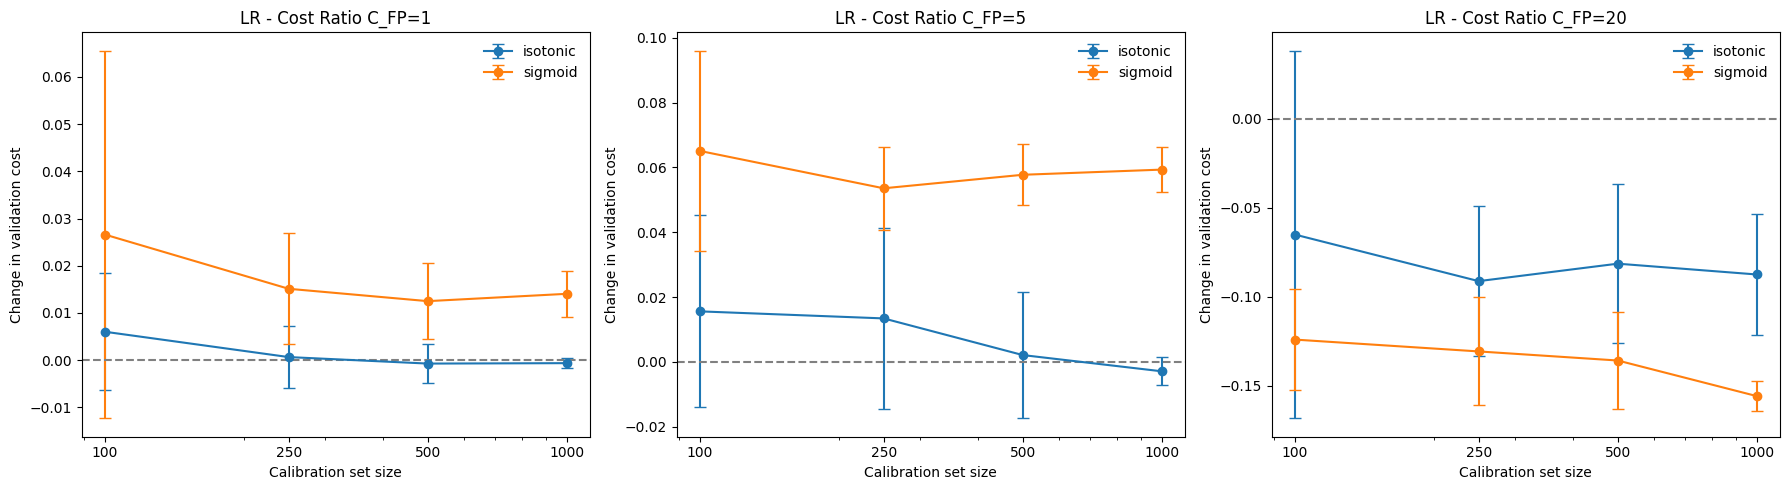

In [17]:
plot_calibration_costs(lr_calibration_results, 'LR')

- **Sigmoid Calibration (Platt Scaling)**:
  - For symmetric and moderate cost ratios ($C_{FP}=1, 5$), Platt scaling increases validation costs compared to the baseline.
  - At a high cost ratio ($C_{FP}=20$), Sigmoid calibration consistently decreases validation costs across all sample sizes ($n$), demonstrating that it helps align probabilities when decision thresholds are highly asymmetric.

- **Isotonic Calibration**:
  - At small calibration sizes ($n=100$), Isotonic calibration overfits and increases validation costs.
  - At $C_{FP}=5$, Isotonic calibration successfully decreases expected costs only at $n = 1000$, showing that non-parametric adjustments are effective when supported by sufficient data.
  - At $C_{FP}=10$, Isotonic calibration decreases the expected cost even at $n=100$.

## 3.5. Confidence Interval

We will further analyze the effect of calibration by constructing a paired **bootstrap confidence interval** for the change in validation cost (`calibrated_cost - uncalibrated_cost`) over the 50 random calibration draws. Under this framework, if the 95% confidence interval contains zero, the calibration method's effect is considered a **tie** (statistically indistinguishable from the baseline).

In [18]:
def bootstrap_ci(cal_res, calibration_draws):
    """
    Compute a bootstrap interval for the paired difference (calibrated_cost - uncalibrated_cost)
    for each group of (method, n, c_fp)
    """
    bootstrap_results = []

    base_model = cal_res.query("method == 'none'")

    for c_fp in cal_res['c_fp'].unique():
        base_cost = base_model[base_model['c_fp'] == c_fp]['cost'].iloc[0]

        groups_to_eval = []
        for draw in calibration_draws:
            groups_to_eval.append(('sigmoid', draw))
        for draw in calibration_draws:
            groups_to_eval.append(('isotonic', draw))

        for method, n in groups_to_eval:
            calibrated_costs = cal_res[(cal_res.method == method) & (cal_res.n == n) & (cal_res.c_fp == c_fp)].cost.values
            differences = calibrated_costs - base_cost

            # Bootstrap resampling
            rng = np.random.default_rng(SEED)
            boot_means = []
            for _ in range(10_000):
                boot_sample = rng.choice(differences, size=len(differences), replace=True)
                boot_means.append(np.mean(boot_sample))

            # Calculate 95% percentile confidence interval
            ci_lower = np.percentile(boot_means, 2.5)
            ci_upper = np.percentile(boot_means, 97.5)
            mean_diff = np.mean(differences)

            # Determine if it is a tie (0 is inside the interval)
            is_tie = ci_lower <= 0 <= ci_upper

            bootstrap_results.append({
                'c_fp': c_fp,
                'method': method,
                'n': n,
                'mean_difference': mean_diff,
                '95% CI Lower': ci_lower,
                '95% CI Upper': ci_upper,
                'outcome': 'Tie' if is_tie else ('Increase' if mean_diff > 0 else 'Decrease')
            })

    bootstrap_df = pd.DataFrame(bootstrap_results)
    return bootstrap_df

In [24]:
bootstrap_df = bootstrap_ci(lr_calibration_results, (100, 250, 500, 1000))
display(bootstrap_df.round(6))

,c_fp,method,n,mean_difference,95% CI Lower,95% CI Upper,outcome
0,1,sigmoid,100,0.026608,0.017162,0.038715,Increase
1,1,sigmoid,250,0.015122,0.011929,0.018448,Increase
2,1,sigmoid,500,0.012506,0.010288,0.014856,Increase
3,1,sigmoid,1000,0.014058,0.012772,0.015432,Increase
4,1,isotonic,100,0.006031,0.002793,0.009534,Increase
5,1,isotonic,250,0.000665,-0.001020,0.002661,Tie
6,1,isotonic,500,-0.000710,-0.001729,0.000576,Tie
7,1,isotonic,1000,-0.000621,-0.000931,-0.000310,Decrease
8,5,sigmoid,100,0.065100,0.056940,0.073837,Increase
9,5,sigmoid,250,0.053570,0.049889,0.056896,Increase


By analyzing the 95% bootstrap confidence intervals for the cost differences (`calibrated_cost - uncalibrated_cost`) on Logistic Regression, we find:

- **Sigmoid Calibration (Platt Scaling)**:
  - At $C_{FP}=1$ and $C_{FP}=5$, Platt scaling results in a statistically significant **increase** (deterioration) in validation cost.
  - At $C_{FP}=20$, Sigmoid calibration yields a statistically significant **decrease** (improvement) in cost across all calibration sample sizes ($n \ge 100$).

- **Isotonic Calibration**:
  - At small cost ratios ($C_{FP}=1, 5$) and sample sizes ($n \le 500$), the calibration effect is statistically classified as a **tie** (or an increase) due to the high variance of non-parametric estimation with limited data.
  - At higher cost ratios ($C_{FP}=20$), Isotonic calibration achieves a statistically significant **decrease** (improvement) in validation cost as sample size increases ($n \ge 500$).

# Part 4: Random Forest

## 4.1. Model Training

As a comparison, we will train a Random Forest. We will train the model on the **training set** and draw a **reliability diagram** of the model evaluated on the **validation set**.

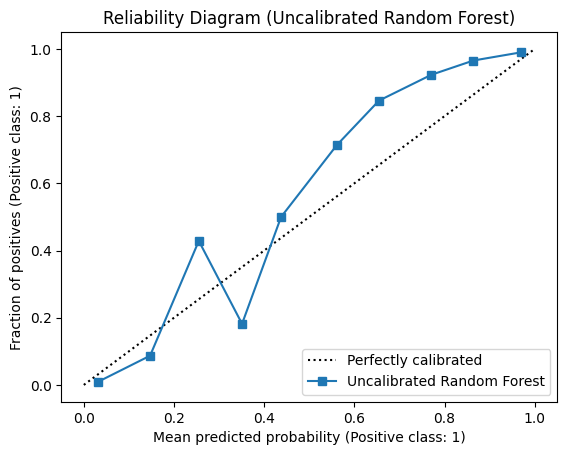

In [20]:
# Train the Random Forest model on training data
spam_rf = create_pipeline(RandomForestClassifier(random_state=SEED), [], spam_feature_cols)
spam_rf.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on validation set
CalibrationDisplay.from_estimator(spam_rf, X_spam_val, y_spam_val, n_bins=10, name="Uncalibrated Random Forest")
plt.title("Reliability Diagram (Uncalibrated Random Forest)")
plt.show()

## 4.2. Model Calibration

Unlike Logistic Regression, which naturally outputs calibrated-like probabilities because it optimizes the sigmoid-based Log-Loss, a Random Forest classifier is an ensemble of decision trees. Individual trees output fraction-of-votes probabilities that tend to be pushed away from $0$ and $1$ (resulting in a sigmoidal shape in its reliability diagram). Therefore, calibration techniques like Platt scaling (`sigmoid`) and `isotonic` regression are expected to significantly improve the predicted probabilities and lower overall decision costs.

We will run the calibration routine for Random Forest using the same methodology: drawing 100, 250, 500, and 1,000 samples from the calibration set over 50 random draws to observe how calibration size impacts validation costs.

In [21]:
# Run the calibration draws for Random Forest
rng = np.random.default_rng(SEED)
rows_rf = []

for c_fp in C_FP:
    rows_rf.append((c_fp, 'none', 0, *score(spam_rf, X_spam_val, y_spam_val, c_fp, C_FN)))
    for n in (100, 250, 500, 1000):
        for _ in range(N_DRAWS):
            idx = rng.choice(len(y_spam_cal), n, replace=False)
            for method in ('sigmoid', 'isotonic'):
                cal = CalibratedClassifierCV(FrozenEstimator(spam_rf), method=method)
                cal.fit(X_spam_cal.iloc[idx], y_spam_cal.iloc[idx])
                rows_rf.append((c_fp, method, n, *score(cal, X_spam_val, y_spam_val, c_fp, C_FN)))

rf_calibration_results = pd.DataFrame(rows_rf, columns=['c_fp', 'method', 'n', 'brier', 'logloss', 'cost'])

for col in ['c_fp', 'n', 'brier', 'logloss', 'cost']:
    rf_calibration_results[col] = pd.to_numeric(rf_calibration_results[col], errors='coerce')

print(rf_calibration_results.groupby(['c_fp', 'method', 'n']).agg(['mean', 'std']).round(4))

                     brier         logloss            cost        
                      mean     std    mean     std    mean     std
c_fp method   n                                                   
1    isotonic 100   0.0542  0.0050  0.7836  0.4649  0.0678  0.0108
              250   0.0524  0.0025  0.3855  0.2860  0.0669  0.0069
              500   0.0507  0.0013  0.2303  0.0947  0.0646  0.0053
              1000  0.0512  0.0007  0.1839  0.0099  0.0665  0.0051
     none     0     0.0501     NaN  0.1802     NaN  0.0599     NaN
     sigmoid  100   0.0502  0.0042  0.1831  0.0155  0.0629  0.0061
              250   0.0493  0.0013  0.1784  0.0054  0.0612  0.0033
              500   0.0487  0.0008  0.1754  0.0032  0.0600  0.0019
              1000  0.0487  0.0005  0.1751  0.0020  0.0594  0.0012
5    isotonic 100   0.0547  0.0042  0.8683  0.4447  0.1240  0.0237
              250   0.0518  0.0023  0.3916  0.2208  0.1165  0.0060
              500   0.0512  0.0013  0.2226  0.0542  0.1206  0.

## 4.3. Plotting Costs

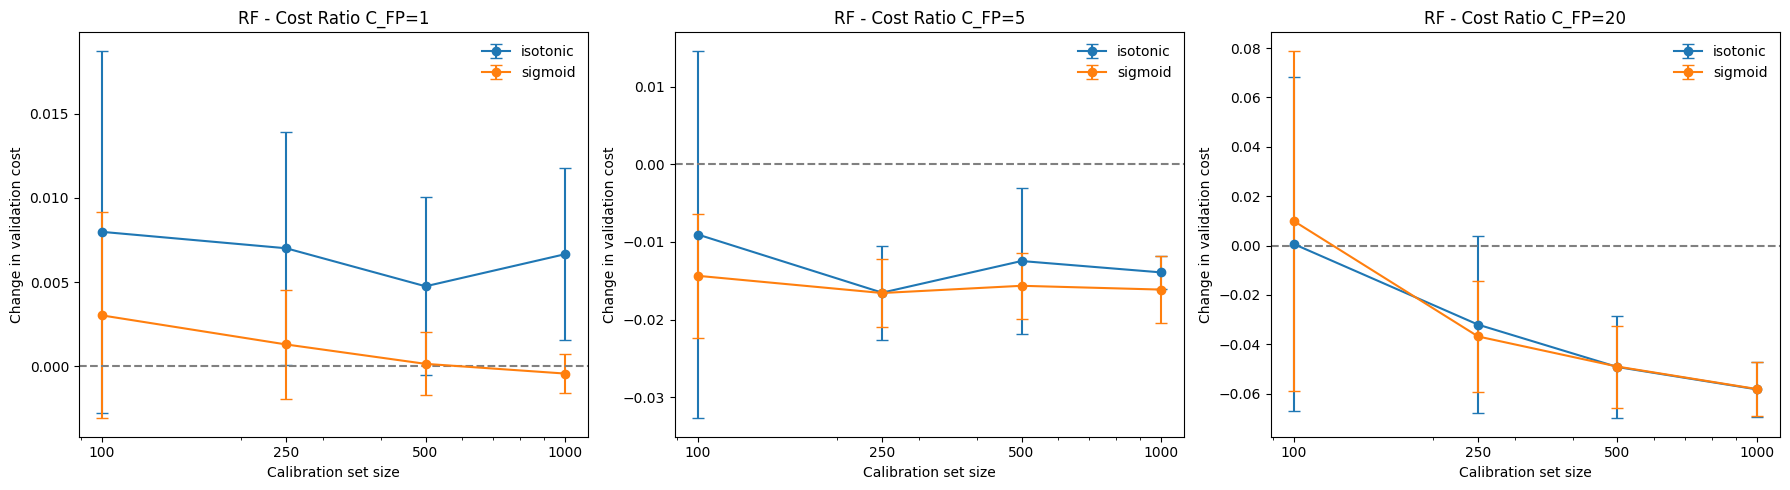

In [22]:
# Plot the change in validation cost for Random Forest
plot_calibration_costs(rf_calibration_results, 'RF')

- **Sigmoid Calibration (Platt Scaling)**:
  - For a symmetric cost ratio ($C_{FP}=1$), Platt scaling has a neutral or slightly negative effect on costs.
  - At higher cost ratios ($C_{FP}=5, 20$), Sigmoid calibration consistently and substantially decreases validation costs across all sample sizes ($n$). Since Random Forests suffer from systematic voting-fraction biases, Platt scaling successfully flattens this distortion.

- **Isotonic Calibration**:
  - At symmetric cost ratio ($C_{FP}=1$), Isotonic calibration overfits and increases expected validation costs.
  - At higher cost ratios ($C_{FP}=5, 20$), Isotonic calibration successfully decreases expected costs as calibration size increases, ultimately matching or outperforming Sigmoid calibration at $n=1000$.

## 4.4. Confidence Interval

In [23]:
# Calculate Bootstrap Confidence Intervals for Random Forest
rf_bootstrap_df = bootstrap_ci(rf_calibration_results, (100, 250, 500, 1000))
display(rf_bootstrap_df.round(6))

,c_fp,method,n,mean_difference,95% CI Lower,95% CI Upper,outcome
0,1,sigmoid,100,0.003016,0.001508,0.004922,Increase
1,1,sigmoid,250,0.001286,0.000399,0.002217,Increase
2,1,sigmoid,500,0.000133,-0.000355,0.000666,Tie
3,1,sigmoid,1000,-0.000443,-0.000754,-0.000133,Decrease
4,1,isotonic,100,0.007982,0.005233,0.011220,Increase
5,1,isotonic,250,0.007007,0.005144,0.009002,Increase
6,1,isotonic,500,0.004745,0.003326,0.006208,Increase
7,1,isotonic,1000,0.006652,0.005277,0.008115,Increase
8,5,sigmoid,100,-0.014368,-0.016497,-0.012150,Decrease
9,5,sigmoid,250,-0.016585,-0.017827,-0.015432,Decrease


By analyzing the 95% bootstrap confidence intervals for the cost differences (`calibrated_cost - uncalibrated_cost`), we find:

- **Sigmoid Calibration (Platt Scaling)**:
  - At a symmetric cost ratio ($C_{FP}=1$), small sample sizes ($N=100, 250$) slightly **increase** costs, but stabilize to a **decrease** at $N=1000$.
  - At higher cost ratios ($C_{FP}=5, 20$), Sigmoid calibration consistently results in a statistically significant **decrease** in cost for all sample sizes ($n \ge 250$, with a **tie** at $n=100$). This shows that Platt scaling successfully corrects the biased, central-tendency probabilities typical of Random Forests.

- **Isotonic Calibration**:
  - At symmetric cost ratio ($C_{FP}=1$) and small sample sizes ($n=100$), Isotonic calibration overfits, causing an **increase** in cost.
  - At higher cost ratios ($C_{FP}=5, 20$), Isotonic calibration achieves a statistically significant **decrease** in validation costs for almost all sample sizes ($n \ge 250$, with a **tie** at $n=100$). This confirms that when the cost penalty for false positives is high, non-parametric calibration is highly effective even with moderate amounts of calibration data.